I got this dataset from Kaggle. It’s a CSV file called Student Mental Health that includes survey responses from university students. The dataset has around 100 rows and 11 columns. It includes basic demographic information (like gender, age, and marital status), academic details (course, CGPA, and year of study), and mental health indicators (whether the student has depression, anxiety, or panic attacks).

Most of the variables are categorical, and only “Age” is numerical. The dataset looks clean and simple, which makes it easy to work with for this project.

Dataset Source: https://www.kaggle.com/datasets/aminasalamat/mental-health-of-students-dataset

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

for file_name in uploaded.keys():
    print("Uploaded file:", file_name)
    df = pd.read_csv(file_name)

df.head()


Saving Student Mental health.csv to Student Mental health.csv
Uploaded file: Student Mental health.csv


,Timestamp,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?
0,8/7/2020 12:02,Female,18.0,Engineering,year 1,3.00 - 3.49,No,Yes,No,Yes,No
1,8/7/2020 12:04,Male,21.0,Islamic education,year 2,3.00 - 3.49,No,No,Yes,No,No
2,8/7/2020 12:05,Male,19.0,BIT,Year 1,3.00 - 3.49,No,Yes,Yes,Yes,No
3,8/7/2020 12:06,Female,22.0,Laws,year 3,3.00 - 3.49,Yes,Yes,No,No,No
4,8/7/2020 12:13,Male,23.0,Mathemathics,year 4,3.00 - 3.49,No,No,No,No,No


In [ ]:
df.info()
df.isna().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 11 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Timestamp                                     101 non-null    object 
 1   Choose your gender                            101 non-null    object 
 2   Age                                           100 non-null    float64
 3   What is your course?                          101 non-null    object 
 4   Your current year of Study                    101 non-null    object 
 5   What is your CGPA?                            101 non-null    object 
 6   Marital status                                101 non-null    object 
 7   Do you have Depression?                       101 non-null    object 
 8   Do you have Anxiety?                          101 non-null    object 
 9   Do you have Panic attack?                     101 non-null    obj

,0
Timestamp,0
Choose your gender,0
Age,1
What is your course?,0
Your current year of Study,0
What is your CGPA?,0
Marital status,0
Do you have Depression?,0
Do you have Anxiety?,0
Do you have Panic attack?,0


In [ ]:
df = df.drop(columns=["Timestamp"], errors="ignore")

In [ ]:
df.describe(include='all')

,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?
count,101,100.00000,101,101,101,101,101,101,101,101
unique,2,NaN,49,7,6,2,2,2,2,2
top,Female,NaN,BCS,year 1,3.50 - 4.00,No,No,No,No,No
freq,75,NaN,18,41,47,85,66,67,68,95
mean,NaN,20.53000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,2.49628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,18.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,18.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,19.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,23.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


When I looked at the summary stats, most of the dataset is categorical, so the table mainly shows the top categories and how often they appear. There are more female students in the dataset, and most of the students are between 18 and 24 years old, with an average age of around 20. A lot of students are in year 1, and the most common CGPA range is 3.50–4.00. For mental health, more students selected “No” for depression, anxiety, and panic attacks, but there is still a noticeable portion who selected “Yes.” Very few students sought treatment.

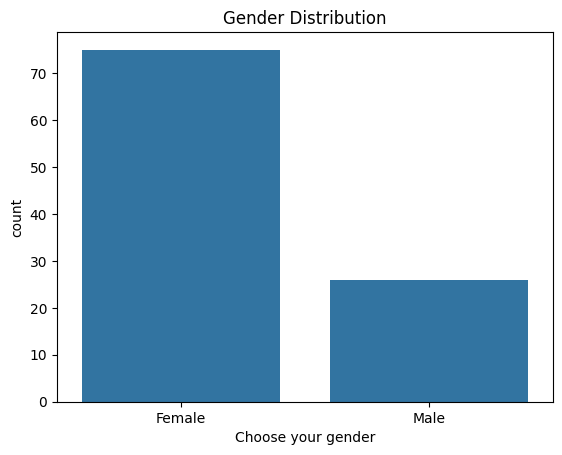

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="Choose your gender", data=df)
plt.title("Gender Distribution")
plt.show()


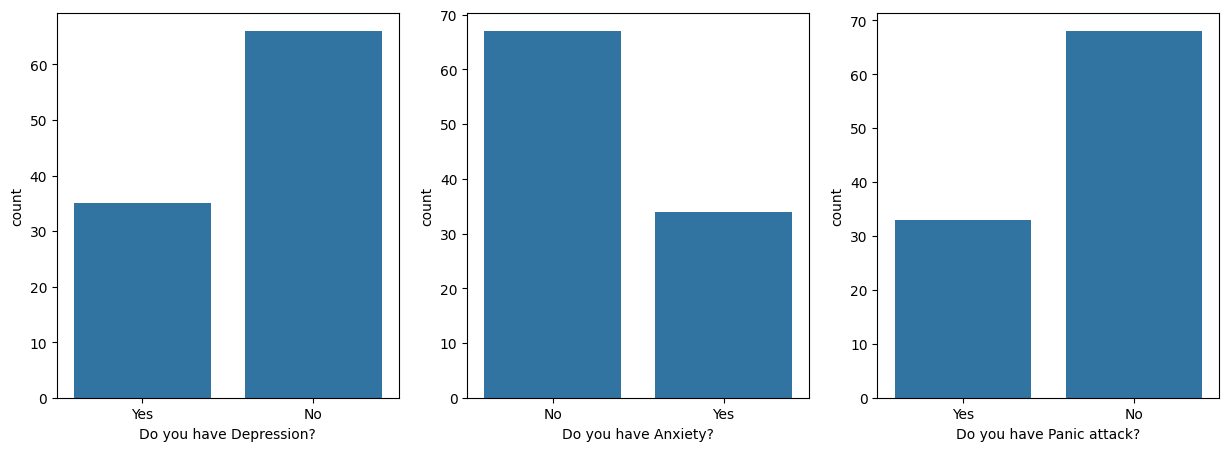

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15,5))

sns.countplot(ax=axes[0], x="Do you have Depression?", data=df)
sns.countplot(ax=axes[1], x="Do you have Anxiety?", data=df)
sns.countplot(ax=axes[2], x="Do you have Panic attack?", data=df)

plt.show()


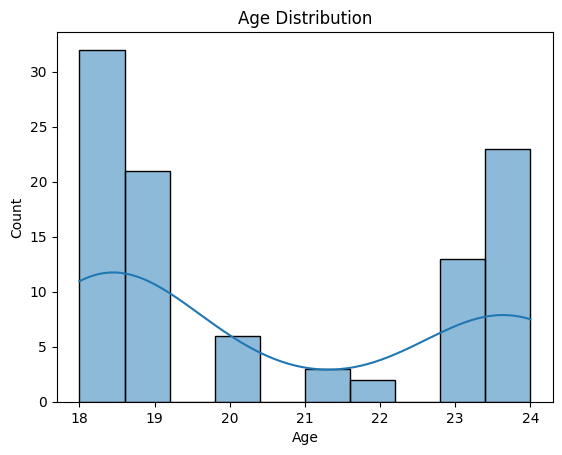

In [ ]:
sns.histplot(df["Age"], bins=10, kde=True)
plt.title("Age Distribution")
plt.show()


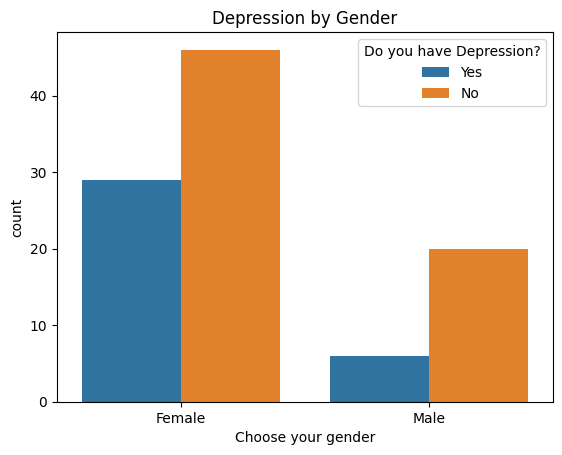

In [ ]:
sns.countplot(x="Choose your gender", hue="Do you have Depression?", data=df)
plt.title("Depression by Gender")
plt.show()


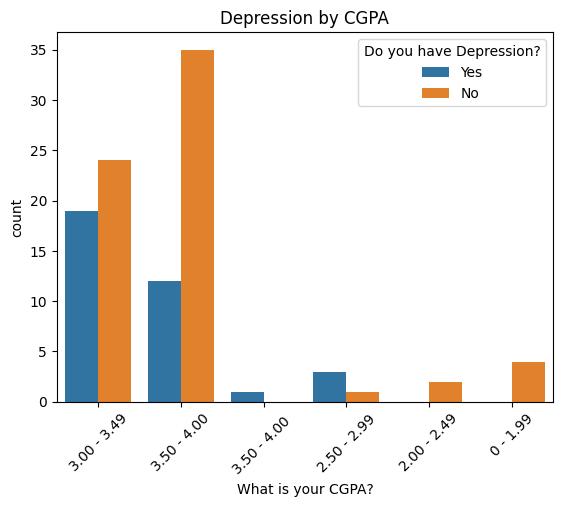

In [ ]:
sns.countplot(x="What is your CGPA?", hue="Do you have Depression?", data=df)
plt.xticks(rotation=45)
plt.title("Depression by CGPA")
plt.show()


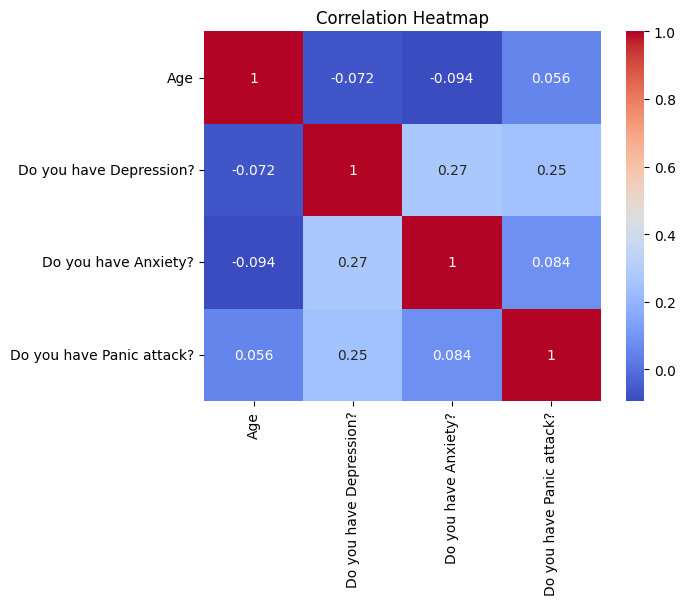

In [ ]:
import numpy as np

df_encoded = df.copy()

mapping = {"Yes":1, "No":0}
for col in ["Do you have Depression?", "Do you have Anxiety?", "Do you have Panic attack?"]:
    df_encoded[col] = df_encoded[col].map(mapping)

numeric_df = df_encoded.select_dtypes(include=np.number)
corr = numeric_df.corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df["Choose your gender"], df["Do you have Depression?"])
chi2, p, dof, expected = chi2_contingency(table)

chi2, p


(np.float64(1.4408896103896098), np.float64(0.22999543639902997))

The chi-square test gave a p-value of about 0.23. Since this is higher than 0.05, it means the relationship between gender and depression is not statistically significant in this dataset. Gender does not seem to be a strong factor for whether a student reports depression here. The sample size is also small, so the results might not represent all students, but based on this dataset, there is no strong connection.

Problem Statement

Mental health challenges among university students have become increasingly common due to academic pressure, social expectations, and personal stress. Depression, in particular, can significantly affect a student’s academic performance, motivation, and overall well-being. Early identification of students who may be at risk can help schools provide support services and reduce negative outcomes.

The goal of this project is to build a machine learning classification model that predicts whether a student is likely to experience depression based on demographic and academic factors such as age, gender, course of study, year of study, and CGPA. The dataset used in this project comes from an anonymous survey of university students and includes self-reported mental health indicators, making it suitable for analyzing patterns related to student well-being.

The main stakeholders for this project include university counseling centers, student mental health support units, academic advisors, and policymakers focused on student welfare. If the model performs well, it could help identify patterns in student groups who may be at higher risk and guide proactive outreach or awareness campaigns.

To solve this problem, classification algorithms such as Logistic Regression, Decision Trees, Random Forest, and K-Nearest Neighbors may be appropriate. However, challenges such as the presence of categorical variables, possible imbalance in the dataset (more “No” than “Yes”), and the sensitivity of mental health-related predictions must be considered. The purpose of this model is not to diagnose mental health conditions, but to support institutions in understanding risk factors and improving student support programs.

Before building the models, I made sure all the data was in a format machine learning algorithms can actually use. Most of the dataset is categorical (gender, course, CGPA, year of study, etc.), so I converted these columns using one-hot encoding. The mental health columns (depression, anxiety, and panic attack) were already mapped to 0s and 1s earlier, so they were ready to go.

I dropped the timestamp column since it doesn’t tell the model anything useful. Age stayed numeric, and I didn’t need to scale anything because most of the models I chose don’t require strict scaling.

Overall, the goal was to keep the useful features and prepare them in a clean numeric format so the models can actually learn from them.

In [ ]:
import pandas as pd
df = pd.read_csv("Student Mental health.csv")
df_model = df.copy()


mapping = {"Yes": 1, "No": 0}
for col in ["Do you have Depression?", "Do you have Anxiety?", "Do you have Panic attack?"]:
    df_model[col] = df_model[col].map(mapping)


df_model = pd.get_dummies(df_model, drop_first=True)

df_model.head()

,Age,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Timestamp_13/07/2020 10:10:30,Timestamp_13/07/2020 10:11:26,Timestamp_13/07/2020 10:12:18,Timestamp_13/07/2020 10:12:26,Timestamp_13/07/2020 10:12:28,Timestamp_13/07/2020 10:14:46,...,Your current year of Study_year 2,Your current year of Study_year 3,Your current year of Study_year 4,What is your CGPA?_2.00 - 2.49,What is your CGPA?_2.50 - 2.99,What is your CGPA?_3.00 - 3.49,What is your CGPA?_3.50 - 4.00,What is your CGPA?_3.50 - 4.00,Marital status_Yes,Did you seek any specialist for a treatment?_Yes
0,18.0,1,0,1,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
1,21.0,0,1,0,False,False,False,False,False,False,...,True,False,False,False,False,True,False,False,False,False
2,19.0,1,1,1,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
3,22.0,1,0,0,False,False,False,False,False,False,...,False,True,False,False,False,True,False,False,True,False
4,23.0,0,0,0,False,False,False,False,False,False,...,False,False,True,False,False,True,False,False,False,False


I used an 80/20 train-test split so the model is trained on most of the data but still tested on new data it hasn't seen before.

In [ ]:
from sklearn.model_selection import train_test_split

X = df_model.drop("Do you have Depression?", axis=1)
y = df_model["Do you have Depression?"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Model Choices

Since this is a classification set, I tried a few common models like:

Logistic Regression - simple, fast, and interpretable

Decision Tree - easy to understand and works well with categorical data

Random Forest - usually performs better because it uses many decision trees

K-Nearest Neighbors (KNN) - simple distance-based method

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "KNN": KNeighborsClassifier()
}

results = {}

nan_rows_train = X_train.isnull().any(axis=1)
X_train_cleaned = X_train[~nan_rows_train]
y_train_cleaned = y_train[~nan_rows_train]

nan_rows_test = X_test.isnull().any(axis=1)
X_test_cleaned = X_test[~nan_rows_test]
y_test_cleaned = y_test[~nan_rows_test]


for name, model in models.items():
    model.fit(X_train_cleaned, y_train_cleaned)
    y_pred = model.predict(X_test_cleaned)
    acc = accuracy_score(y_test_cleaned, y_pred)
    results[name] = acc
    print(f"{name} Accuracy:", acc)

Logistic Regression Accuracy: 0.7142857142857143
Decision Tree Accuracy: 0.6190476190476191
Random Forest Accuracy: 0.7619047619047619
KNN Accuracy: 0.7142857142857143


Final Model Selection Based on the accuracy scores, Random Forest performed the best with an accuracy of about 0.76. Since Random Forest uses multiple decision trees and averages their results, it handles mixed data types really well and avoids overfitting better than a single Decision Tree. Because of that, I am choosing Random Forest as my final model for this project. It gave the most consistent and reliable results compared to the other models.

# CONCLUSION

Key Findings

From the exploratory data analysis, I learned that most students in the dataset are between 18 and 24 years old, and a large portion are first-year students. The most common CGPA range was 3.50 - 4.00. For the mental health indicators, most students selected “No” for depression, anxiety, and panic attacks, but there was still a noticeable percentage who selected “Yes.” Treatment-seeking was very low across the dataset.

The chi-square test showed that gender was not significantly related to depression (p = 0.23), meaning gender did not play a strong statistical role in this dataset. The correlation heatmap also showed very weak relationships between depression and the other numeric variables, so no single feature had a strong direct connection to depression.

After training multiple classification models, Random Forest performed the best with an accuracy of around 0.76. Logistic Regression and KNN were close behind, while Decision Tree had the lowest accuracy. Random Forest was the strongest overall and became the final model for this project.

Problem Resolution

The main goal of this project was to see whether demographic and academic information could help predict which students may be more likely to experience depression. Even though the dataset is small and the relationships between features and depression are weak, the Random Forest model was still able to produce reasonable predictions. The model does not replace any clinical diagnosis, but it can help identify general patterns and highlight student groups who may need additional support.

Overall, the model provides value by helping universities understand potential risk factors using simple, accessible data.

Deployment

If this model were used in a real-world setting, it would probably be part of a larger student wellness system.

Prediction frequency: once per semester when student data updates

Human vs automation: humans (counselors or advisors) should review all results

Model retraining: every 1-2 semesters or whenever new data trends appear

The purpose of deployment would be to support earlier outreach and resource planning, not to label or diagnose students

Improvements

If I continued this project, the improvements I would focus on include:

Collecting more data, since the current dataset is small

Adding more meaningful features (sleep, workload, stress levels, social support, etc.)

Using class-balancing methods like SMOTE to address the imbalance

Trying additional models such as Gradient Boosting or XGBoost

Performing proper hyperparameter tuning for each model

These changes would likely improve accuracy and make the model more useful in a real student support system.